# **TUGAS UTS**

## Nama  : Ananda Sakinah
## NIM   : 23031554060
## Kelas : 2023-E

## 1.2 Penggunaan driver Neo4J

In [1]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"  
AUTH = ("neo4j", "neo4jbaru")   


In [2]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j", )

In [2]:
import neo4j
print(neo4j.__version__)

6.4.1


In [4]:
import sys, neo4j
print(sys.executable)
print(neo4j.__version__)

d:\Semester 7\Tugas\Graf Sains Data\Tugas UTS_Ananda Sakinah_23031554060_2023-E\myvenv_uts\Scripts\python.exe
6.4.1


In [6]:
from neo4j import GraphDatabase, RoutingControl
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name", name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])
        
with GraphDatabase.driver(URI, auth=AUTH) as driver: 
    add_friend(driver, "Arthur", "Guinevere") 
    add_friend(driver, "Arthur", "Lancelot") 
    add_friend(driver, "Arthur", "Merlin") 
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


## **Impor Data dari RetailRocket ke Database Neo4j**

1. Unduh data dari kaggle dengan perintah
2. Fitur yang diunduh meliputi:

| Fitur | Keterangan |
| :--- | :--- |
| timestamp | Waktu dalam format unix epoch |
| visitorid | ID unik pengunjung |
| event | Jenis interaksi default: view, addtocart, transaction |
| itemid | ID unik produk |
| transactionid | ID transaksi, hanya terisi saat event berjenis ’transaction |

In [4]:
import pandas as pd
print(pd.__version__)

2.3.3


In [5]:
import pandas as pd
df = pd.read_csv("data/events.csv")
print(df.shape)
print(df.head())
print(df["event"].value_counts())

(2756101, 5)
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [7]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("neo4j://127.0.0.1:7687", auth=("neo4j", "neo4jbaru"))
session = driver.session(database="system")

In [8]:
driver.verify_connectivity()
print(session.run("SHOW DATABASES").data())

[{'name': 'neo4j', 'type': 'standard', 'aliases': [], 'access': 'read-write', 'address': 'localhost:7687', 'role': 'primary', 'writer': True, 'requestedStatus': 'online', 'currentStatus': 'online', 'statusMessage': '', 'default': True, 'home': True, 'constituents': []}, {'name': 'system', 'type': 'system', 'aliases': [], 'access': 'read-write', 'address': 'localhost:7687', 'role': 'primary', 'writer': True, 'requestedStatus': 'online', 'currentStatus': 'online', 'statusMessage': '', 'default': False, 'home': False, 'constituents': []}]


### Agparse

In [9]:
import os
import sys
import argparse
from neo4j import GraphDatabase

def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4j."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="neo4jbaru",
        help="Password Neo4J (default: neo4j)",
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
    )
    return parser.parse_args([])  
args = parse_arguments()
print(args)

Namespace(user='neo4j', password='neo4jbaru', bolt='neo4j://127.0.0.1:7687', source='data')


### Peemriksaan events.csv

In [10]:
csv_file_path = os.path.join(args.source, "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

### Pembuatan Koneksi

In [12]:
try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
    print("Terhubung ke Neo4j")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

Terhubung ke Neo4j


In [13]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

### Mekanisme *Batch*

In [14]:
import pandas as pd
from tqdm import tqdm

batch_size = 5000

with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_rows = 2756101
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 552/552 [03:21<00:00,  2.74it/s]

Proses impor berhasil.


### Impor data dalam CYPHER

In [15]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

## **2.1 Wrangling dan EDA**

### Soal nomor 1- 2
1. Menentukan Periode waktu:

| Fold Training (P1) | Fold Tasting (P2) |
| :--- | :--- |
| 08/05/2015 - 27/07/2015 | 28/07/2015 - 17/08/2015 |

2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [ ]:
df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")   

P1 = ("2015-05-08", "2015-07-27")  
P2 = ("2015-07-28", "2015-08-17")  
def filter_periode(df, start, end):
    batas_akhir = pd.Timestamp(end) + pd.Timedelta(days=1)  
    return df[(df["dt"] >= pd.Timestamp(start)) & (df["dt"] < batas_akhir)]

df_p1 = filter_periode(df, *P1).drop(columns="dt")
df_p2 = filter_periode(df, *P2).drop(columns="dt")

df_p1.to_csv("data/events_p1.csv", index=False)
df_p2.to_csv("data/events_p2.csv", index=False)

print("P1:", len(df_p1), "baris | P2:", len(df_p2), "baris")
print(df_p1["event"].value_counts())
print(df_p2["event"].value_counts())

P1: 1710737 baris | P2: 385955 baris
event
view           1655412
addtocart        41699
transaction      13626
Name: count, dtype: int64
event
view           372173
addtocart       10511
transaction      3271
Name: count, dtype: int64


## Soal No.3
 Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

Membuat data frame baru, karena saya tidak ingin menghapus data frame sebelumnya

In [20]:
df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")

P1 = ("2015-05-08", "2015-07-27")
P2 = ("2015-07-28", "2015-08-17")

def filter_periode(df, start, end):
    batas_akhir = pd.Timestamp(end) + pd.Timedelta(days=1)
    return df[(df["dt"] >= pd.Timestamp(start)) & (df["dt"] < batas_akhir)]

df_p1 = filter_periode(df, *P1).drop(columns="dt")
df_p2 = filter_periode(df, *P2).drop(columns="dt")
df_p1.to_csv("data/events_p1.csv", index=False)
df_p2.to_csv("data/events_p2.csv", index=False)
print("P1:", len(df_p1), "| P2:", len(df_p2))

P1: 1710737 | P2: 385955


In [21]:
driver = GraphDatabase.driver("neo4j://127.0.0.1:7687", auth=("neo4j", "neo4jbaru"))
DB = "utsp1"

driver.execute_query(f"CREATE DATABASE {DB} IF NOT EXISTS WAIT", database_="system")
print(driver.execute_query("SHOW DATABASES", database_="system")[0])

[<Record name='neo4j' type='standard' aliases=[] access='read-write' address='localhost:7687' role='primary' writer=True requestedStatus='online' currentStatus='online' statusMessage='' default=True home=True constituents=[]>, <Record name='system' type='system' aliases=[] access='read-write' address='localhost:7687' role='primary' writer=True requestedStatus='online' currentStatus='online' statusMessage='' default=False home=False constituents=[]>, <Record name='utsp1' type='standard' aliases=[] access='read-write' address='localhost:7687' role='primary' writer=True requestedStatus='online' currentStatus='online' statusMessage='' default=False home=False constituents=[]>]


In [22]:
csv_file_path = "data/events_p1.csv"
batch_size = 5000
total_rows = sum(1 for _ in open(csv_file_path)) - 1
total_chunks = (total_rows // batch_size) + 1

with driver.session(database=DB) as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        session.execute_write(import_batch, chunk.to_dict(orient="records"))

print("Proses impor berhasil.")

Mengimpor Batch Data: 100%|██████████| 343/343 [02:01<00:00,  2.82it/s]

Proses impor berhasil.


Query komposisi subgraph

In [23]:
q_node = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
"""
q_rel = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
"""

for q in [q_node, q_rel]:
    rec, _, _ = driver.execute_query(q, database_=DB, routing_=RoutingControl.READ)
    print(pd.DataFrame([r.data() for r in rec]), "\n")

  jenis_simpul  jumlah
0      Visitor  870768
1         Item  191284 

    jenis_relasi   jumlah
0         VIEWED  1655412
1  ADDED_TO_CART    41699
2         BOUGHT    13626 



CHYPER SQL yang digunakan antaralain:
1. Ekstraksi Simpul: Perintah MATCH (n) digunakan untuk mengambil seluruh simpul di dalam database, di mana label spesifik simpul (seperti Visitor atau Item) diidentifikasi melalui fungsi labels(n)[0].
2. Pengelompokan Data: Penerapan fungsi agregasi count(n) bersama dengan kolom non-agregasi memicu Cypher untuk melakukan pengelompokan data berbasis label simpul, serupa dengan fungsi GROUP BY pada SQL.
3. Identifikasi Relasi berarah: Klausa MATCH ()-[r]->() digunakan untuk memetakan seluruh hubungan searah, diikuti penggunaan fungsi type(r) untuk membaca tipe interaksi yang terjadi (VIEWED, ADDED_TO_CART, dan BOUGHT).

Pencocokan -> corrected

In [24]:
print("Visitor unik:", df_p1["visitorid"].nunique())
print("Item unik   :", df_p1["itemid"].nunique())
print(df_p1["event"].value_counts())

Visitor unik: 870768
Item unik   : 191284
event
view           1655412
addtocart        41699
transaction      13626
Name: count, dtype: int64


### Soal nomor 4
Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [25]:
from neo4j import GraphDatabase, Result
from scipy.sparse import csr_matrix

DB = "utsp1"

query = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor,
       i.itemId    AS item,
       sum(CASE type(r) WHEN 'VIEWED' THEN 1
                        WHEN 'ADDED_TO_CART' THEN 3
                        WHEN 'BOUGHT' THEN 5 END) AS skor,
       count(r) AS n_interaksi
"""

edges = driver.execute_query(query, database_=DB, result_transformer_=Result.to_df)
print(edges.shape)
edges.head()

(1328023, 4)


,visitor,item,skor,n_interaksi
0,257597,355908,1,1
1,981382,355908,1,1
2,1102250,355908,1,1
3,62710,355908,1,1
4,76757,355908,1,1


Membangun Vector Space Model (VSM): Matriks User x Item

In [26]:
u_codes, u_index = pd.factorize(edges["visitor"])
i_codes, i_index = pd.factorize(edges["item"])

X_user = csr_matrix(
    (edges["skor"].astype(float), (u_codes, i_codes)),
    shape=(len(u_index), len(i_index))
)
print(X_user.shape)

(870768, 191284)


In [27]:
import numpy as np
n_user, n_item = X_user.shape
nnz = X_user.nnz
total_sel = n_user * n_item

print("Shape matriks User x Item :", X_user.shape)
print("Dimensi vektor tiap user  :", n_item, "(= jumlah Item)")
print("Jumlah sel tidak nol (nnz):", nnz)
print("Density                   :", f"{nnz/total_sel:.8%}")
print("Sparsity                  :", f"{1 - nnz/total_sel:.6%}")
print("Memori sparse (MB)        :", round((X_user.data.nbytes + X_user.indices.nbytes + X_user.indptr.nbytes)/1e6, 1))
print("Memori jika dense (GB)    :", round(total_sel*8/1e9, 1))

# berapa item yg disentuh tiap user
item_per_user = np.diff(X_user.indptr)          
print(pd.Series(item_per_user).describe())
print("User dengan hanya 1 item  :", f"{(item_per_user==1).mean():.1%}")

Shape matriks User x Item : (870768, 191284)
Dimensi vektor tiap user  : 191284 (= jumlah Item)
Jumlah sel tidak nol (nnz): 1328023
Density                   : 0.00079731%
Sparsity                  : 99.999203%
Memori sparse (MB)        : 19.4
Memori jika dense (GB)    : 1332.5
count    870768.000000
mean          1.525117
std           6.247374
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        2362.000000
dtype: float64
User dengan hanya 1 item  : 79.7%


Vector Space Model (VSM) menghasilkan matriks interaksi dengan karakteristik teknis dan distribusi anataralain:

1. Dimensi, Shape, dan Sparsity: Matriks User x Item terbentuk dengan shape 870.768 x 191.284, menghasilkan dimensi vektor sebesar 191.284 untuk setiap user. Dari total kapasitas matriks, tingkat Sparsity mencapai 99,999203% (Density: 0,00079731%) dengan jumlah elemen tidak nol (nnz) sebanyak 1.328.023. Angka ini menunjukkan bahwa hampir seluruh ruang matriks bersifat kosong karena keterbatasan interaksi antar entitas.

2. Distribusi Interaksi User: Distribusi data terpantau sangat miring (skewed). Nilai rata-rata (mean) interaksi berada pada 1,52 item per user, sedangkan nilai median (50%) berada pada angka 1 item. Mayoritas populasi pengguna, yaitu sebesar 79,7% user, hanya berinteraksi dengan 1 item. Ketimpangan ini dilengkapi dengan adanya pengguna dengan aktivitas sangat tinggi (outlier) yang mencapai nilai maksimal 2.362 interaksi.

3. Efisiensi Alokasi Memori: Tingginya nilai sparsity memvalidasi penggunaan format penyimpanan sparse. Jika dipaksakan menggunakan format dense, matriks memerlukan konsumsi memori raksasa sebesar 1.332,5 GB. Dengan mengimplementasikan format sparse, kebutuhan memori berhasil ditekan secara drastis hingga 19,4 MB, sehingga memungkinkan proses analisis data dan pemodelan dilakukan pada infrastruktur komputasi yang efisien.

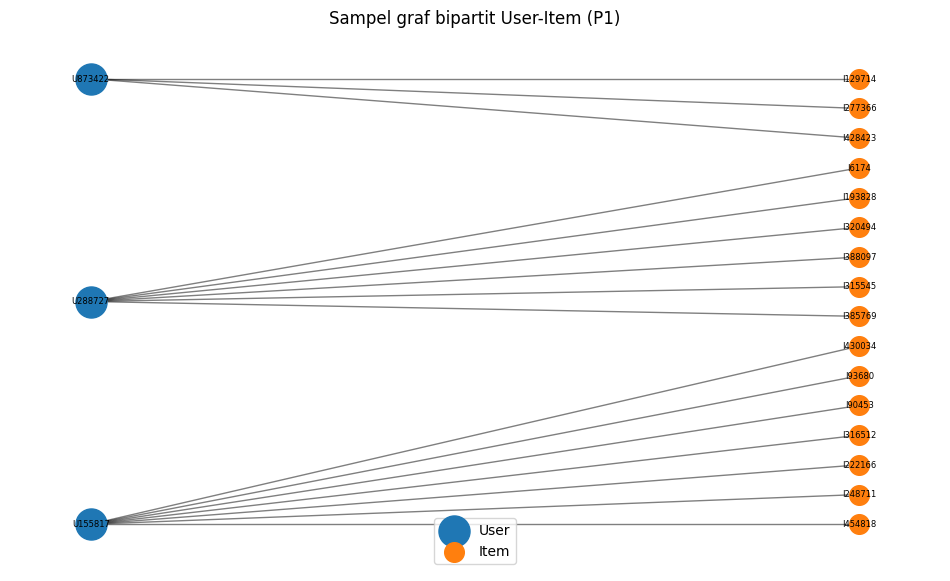

In [29]:
import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
kandidat = np.where(item_per_user >= 3)[0]            # user yang cukup aktif
sampel = rng.choice(kandidat, size=3, replace=False)  # 3 user acak

G = nx.Graph()
for u in sampel:
    baris = X_user[u]
    for j, w in zip(baris.indices, baris.data):
        G.add_node(f"U{u_index[u]}", bipartite=0)
        G.add_node(f"I{i_index[j]}", bipartite=1)
        G.add_edge(f"U{u_index[u]}", f"I{i_index[j]}", weight=w)

users = [n for n, d in G.nodes(data=True) if d["bipartite"] == 0]
items = [n for n, d in G.nodes(data=True) if d["bipartite"] == 1]

plt.figure(figsize=(12, 7))
pos = nx.bipartite_layout(G, users)
nx.draw_networkx_nodes(G, pos, nodelist=users, node_color="tab:blue", node_size=500, label="User")
nx.draw_networkx_nodes(G, pos, nodelist=items, node_color="tab:orange", node_size=200, label="Item")
nx.draw_networkx_edges(G, pos, alpha=0.5)
nx.draw_networkx_labels(G, pos, font_size=6)
plt.legend()
plt.title("Sampel graf bipartit User-Item (P1)")
plt.axis("off")
plt.show()

plot networkx menggunakan sampel kecil karena agar tidak memeuat ribuan sampel

### Soal nomor 5
Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [30]:
X_item = X_user.T.tocsr()     
print(X_item.shape)           

(191284, 870768)


In [ ]:
n_item, n_user = X_item.shape
nnz = X_item.nnz
total_sel = n_item * n_user

print("Shape matriks Item x User :", X_item.shape)
print("Dimensi vektor tiap item  :", n_user, "(= jumlah User)")
print("Jumlah sel tidak nol (nnz):", nnz)
print("Density                   :", f"{nnz/total_sel:.8%}")
print("Sparsity                  :", f"{1 - nnz/total_sel:.6%}")
print("Memori sparse (MB)        :", round((X_item.data.nbytes + X_item.indices.nbytes + X_item.indptr.nbytes)/1e6, 1))
print("Memori jika dense (GB)    :", round(total_sel*8/1e9, 1))

user_per_item = np.diff(X_item.indptr)    
print(pd.Series(user_per_item).describe())
print("Item dengan hanya 1 user  :", f"{(user_per_item==1).mean():.1%}")


top = np.argsort(user_per_item)[::-1][:10]
print(pd.DataFrame({"itemId": i_index[top], "jumlah_user": user_per_item[top]}))

Shape matriks Item x User : (191284, 870768)
Dimensi vektor tiap item  : 870768 (= jumlah User)
Jumlah sel tidak nol (nnz): 1328023
Density                   : 0.00079731%
Sparsity                  : 99.999203%
Memori sparse (MB)        : 16.7
Memori jika dense (GB)    : 1332.5
count    191284.000000
mean          6.942677
std          18.714217
min           1.000000
25%           1.000000
50%           2.000000
75%           6.000000
max        1670.000000
dtype: float64
Item dengan hanya 1 user  : 38.5%
   itemId  jumlah_user
0    5411         1670
1  370653         1132
2  298009          999
3  309778          988
4  335975          910
5   96924          832
6  257040          744
7  354233          735
8  461686          651
9  151444          649


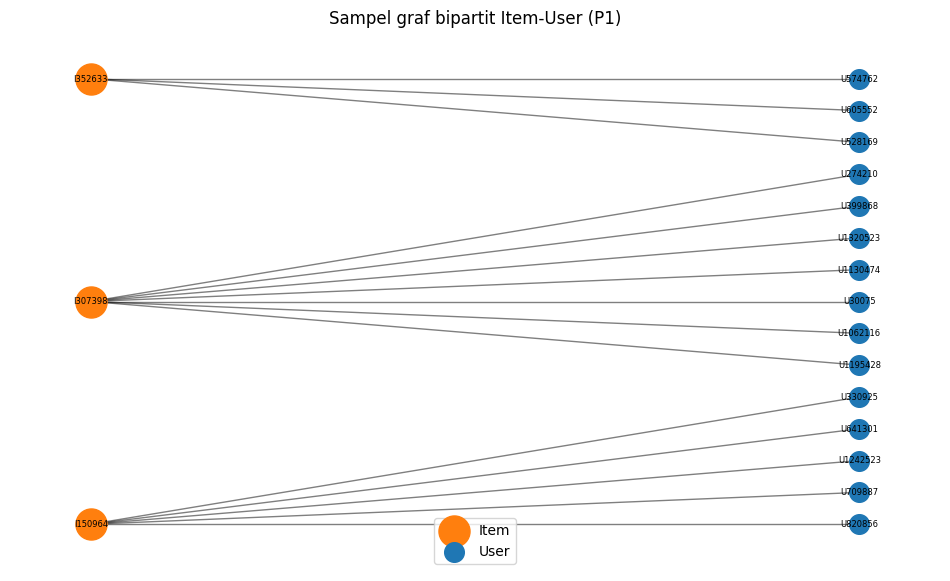

In [ ]:
rng = np.random.default_rng(42)
kandidat = np.where((user_per_item >= 3) & (user_per_item <= 10))[0]   
sampel = rng.choice(kandidat, size=3, replace=False)

G = nx.Graph()
for j in sampel:
    baris = X_item[j]
    for u, w in zip(baris.indices, baris.data):
        G.add_node(f"I{i_index[j]}", bipartite=0)
        G.add_node(f"U{u_index[u]}", bipartite=1)
        G.add_edge(f"I{i_index[j]}", f"U{u_index[u]}", weight=w)

items = [n for n, d in G.nodes(data=True) if d["bipartite"] == 0]
users = [n for n, d in G.nodes(data=True) if d["bipartite"] == 1]

plt.figure(figsize=(12, 7))
pos = nx.bipartite_layout(G, items)
nx.draw_networkx_nodes(G, pos, nodelist=items, node_color="tab:orange", node_size=500, label="Item")
nx.draw_networkx_nodes(G, pos, nodelist=users, node_color="tab:blue", node_size=200, label="User")
nx.draw_networkx_edges(G, pos, alpha=0.5)
nx.draw_networkx_labels(G, pos, font_size=6)
plt.legend()
plt.title("Sampel graf bipartit Item-User (P1)")
plt.axis("off")
plt.show()


KARAKTERISTIK VECTOR SPACE MODEL (SIMPUL ITEM)

1. Dimensi, Shape, dan Sparsity Matriks
Transposisi matriks awal (Xitem = X T user) mengubah ruang vektor menjadi sudut pandang simpul item terhadap user dengan dimensi 191.284 x 870.768. Dimensi ini mengonfirmasi bahwa 191.284 item unik dipetakan ke dalam vektor berdimensi 870.768 user. Matriks ini bersifat highly sparse dengan tingkat Sparsity 99,999203% dan Density 0,00079731%, di mana hanya terdapat 1.328.023 elemen tidak nol (nnz) yang merepresentasikan interaksi aktif riil antar-entitas.

2. Distribusi Popularitas Item (User per Item)
Analisis deskriptif menunjukkan distribusi data yang sangat miring (highly skewed), di mana sebuah item secara rata-rata (mean) hanya berinteraksi dengan 6,94 user (standar deviasi = 18,71), dengan nilai median 2 user dan kuartil atas 6 user. Fenomena Long-Tail terlihat kuat karena 38,5% item hanya memiliki tepat 1 user, menandakan mayoritas katalog tidak populer. Sebaliknya, terdapat pencilan (outlier) popularitas ekstrem pada item ID 5411 (1.670 user), diikuti item 370653 (1.132 user) dan item 298009 (999 user).

3. Efisiensi Alokasi Memori dan Pemilihan Format
Tingginya nilai sparsity memvalidasi penggunaan format penyimpanan Compressed Sparse Row (CSR) demi efisiensi komputasi. Jika disimpan dalam format dense array standar, alokasi memori yang dibutuhkan melonjak hingga 1.332,5 GB, yang melampaui kapasitas infrastruktur komputasi standar. Dengan mengimplementasikan format sparse yang hanya menyimpan indeks aktif dan mengabaikan elemen nol, kebutuhan memori terpangkas drastis menjadi hanya 16,7 MB.

4. Karakteristik Plot Jaringan (NetworkX)
Visualisasi matriks menggunakan NetworkX membentuk graf bipartit (Bipartite Graph), di mana kelompok Item dan User terpisah dan sisi (edge) hanya tercipta antar-kelompok tanpa ada relasi sesama item atau sesama user. Kerapatan sisi yang rendah (0,00079%) membuat graf terlihat sangat renggang dengan mayoritas simpul berderajat rendah. Secara topologi, visualisasi didominasi struktur Hub-and-Spoke di area pusat oleh 10 item terpopuler (hubs) yang memancarkan ribuan sisi ke simpul user, sementara 38,5% item lainnya hanya membentuk struktur periferal linier pendek karena hanya terikat pada 1 user.

### Soal nomor 6
Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

| Karakteristik Matriks          | VSM User (No. 4)        | VSM Item (No. 5)        |
|--------------------------------|-------------------------|-------------------------|
| Shape                          | 870.768 × 191.284       | 191.284 × 870.768       |
| Jumlah vektor                  | 870.768                 | 191.284                 |
| nnz dan sparsity               | 1.328.023; 99,9992%     | 1.328.023; 99,9992%                    |
| Memori sparse                  | 19,4 MB                 | 16,7 MB                 |
| Rata-rata nonzero per vektor   | 1,5                     | 6,9                     |
| Median                         | 1                       | 2                       |
| Vektor hanya punya 1 elemen    | 79,7%                   | 38,5%                   |
| Maksimum                       | 2.362                   | 1.670                   |

Berdasarkan eksplorasi no. 4 dan 5, proyeksi Item dipilih karena lebih efisien dan lebih efektif. Secara efisiensi, jumlah simpul berkurang dari 870.768 menjadi 191.284 (pasangan yang mungkin turun sekitar 20,7 kali) dan biaya komputasi kemiripan sekitar setengahnya. Secara efektivitas, vektor item lebih padat dibanding vektor user (median 2 vs 1 elemen tidak nol; hanya 38,5% item yang disentuh satu user dibanding 79,7% user yang menyentuh satu item), sehingga kemiripan lebih bermakna dan lebih stabil terhadap user baru.

### Soal nomor 7
Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python
1. Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!
2. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

sebelum similarity

In [34]:
q_before = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah"
rec, _, _ = driver.execute_query(q_before, database_=DB, routing_=RoutingControl.READ)
before = pd.DataFrame([r.data() for r in rec])
print(before)

          relasi   jumlah
0         VIEWED  1655412
1  ADDED_TO_CART    41699
2         BOUGHT    13626


hitung simiarity

In [35]:
from sklearn.preprocessing import normalize

Xn  = normalize(X_item, norm="l2", axis=1).tocsr()     
B   = (X_item > 0).astype(np.float32).tocsr()          
XnT = Xn.T.tocsr()
BT  = B.T.tocsr()

K, MIN_COMMON, CHUNK = 5, 2, 2000
hasil = []   

for start in tqdm(range(0, n_item, CHUNK), desc="Hitung similarity"):
    end = min(start + CHUNK, n_item)
    S = (Xn[start:end] @ XnT).tocsr()                  
    C = (B[start:end] @ BT).tocsr()                    

    C.data[C.data < MIN_COMMON] = 0
    C.eliminate_zeros()
    mask = C.copy(); mask.data[:] = 1
    S = S.multiply(mask).tocsr()                       
    S.eliminate_zeros()

    for r in range(end - start):
        a, b = S.indptr[r], S.indptr[r + 1]
        cols, vals = S.indices[a:b], S.data[a:b]
        keep = cols != (start + r)                     
        cols, vals = cols[keep], vals[keep]
        if len(vals) == 0:
            continue
        if len(vals) > K:
            top = np.argpartition(-vals, K)[:K]
            cols, vals = cols[top], vals[top]
        urut = np.argsort(-vals)
        for c, v in zip(cols[urut], vals[urut]):
            hasil.append((start + r, int(c), float(v)))

sim = pd.DataFrame(hasil, columns=["a_idx", "b_idx", "score"])
sim["itemA"] = i_index[sim["a_idx"].to_numpy()].astype(int)
sim["itemB"] = i_index[sim["b_idx"].to_numpy()].astype(int)
sim["score"] = sim["score"].round(6)
sim[["itemA", "itemB", "score"]].to_csv("data/similarity_item_top5.csv", index=False)

print(sim.shape, "| item yang punya tetangga:", sim["itemA"].nunique())
print(sim["score"].describe())

Hitung similarity: 100%|██████████| 96/96 [00:02<00:00, 43.99it/s]


(134072, 5) | item yang punya tetangga: 38657
count    134072.000000
mean          0.246804
std           0.217278
min           0.000300
25%           0.087287
50%           0.172958
75%           0.340439
max           1.000000
Name: score, dtype: float64


5 similarity tertinggi

In [36]:
REF_ITEM = int(i_index[np.argmax(user_per_item)])   
print("Item acuan:", REF_ITEM)
print(sim[sim["itemA"] == REF_ITEM][["itemA", "itemB", "score"]].head(5))

Item acuan: 5411
      itemA   itemB     score
8167   5411   33030  0.145366
8168   5411   33956  0.100019
8169   5411   37807  0.098314
8170   5411  256242  0.092615
8171   5411   89143  0.079983


similarity ke graf

In [37]:
cypher_sim = """
UNWIND $rows AS row
MATCH (a:Item {itemId: row.a})
MATCH (b:Item {itemId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'
"""

def tulis_batch(tx, rows):
    tx.run(cypher_sim, rows=rows)

rows_all = [{"a": int(a), "b": int(b), "score": float(s)}
            for a, b, s in zip(sim["itemA"], sim["itemB"], sim["score"])]

with driver.session(database=DB) as session:
    for i in tqdm(range(0, len(rows_all), 5000), desc="Tulis SIMILAR_TO"):
        session.execute_write(tulis_batch, rows_all[i:i + 5000])
print("Selesai")

Tulis SIMILAR_TO: 100%|██████████| 27/27 [00:14<00:00,  1.84it/s]

Selesai


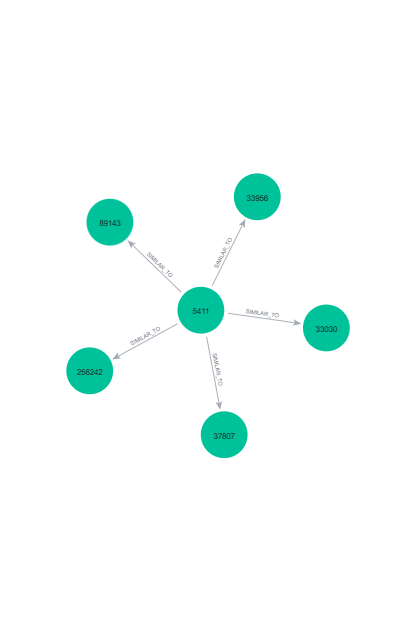

In [38]:
q_top5 = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY s.score DESC
LIMIT 5
"""
rec, _, _ = driver.execute_query(q_top5, ref=REF_ITEM, database_=DB, routing_=RoutingControl.READ)
print(pd.DataFrame([r.data() for r in rec]))

   item_acuan  item_mirip  similarity
0        5411       33030    0.145366
1        5411       33956    0.100019
2        5411       37807    0.098314
3        5411      256242    0.092615
4        5411       89143    0.079983


### Soal nomor 8
Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

**Graff sebelum similarity**


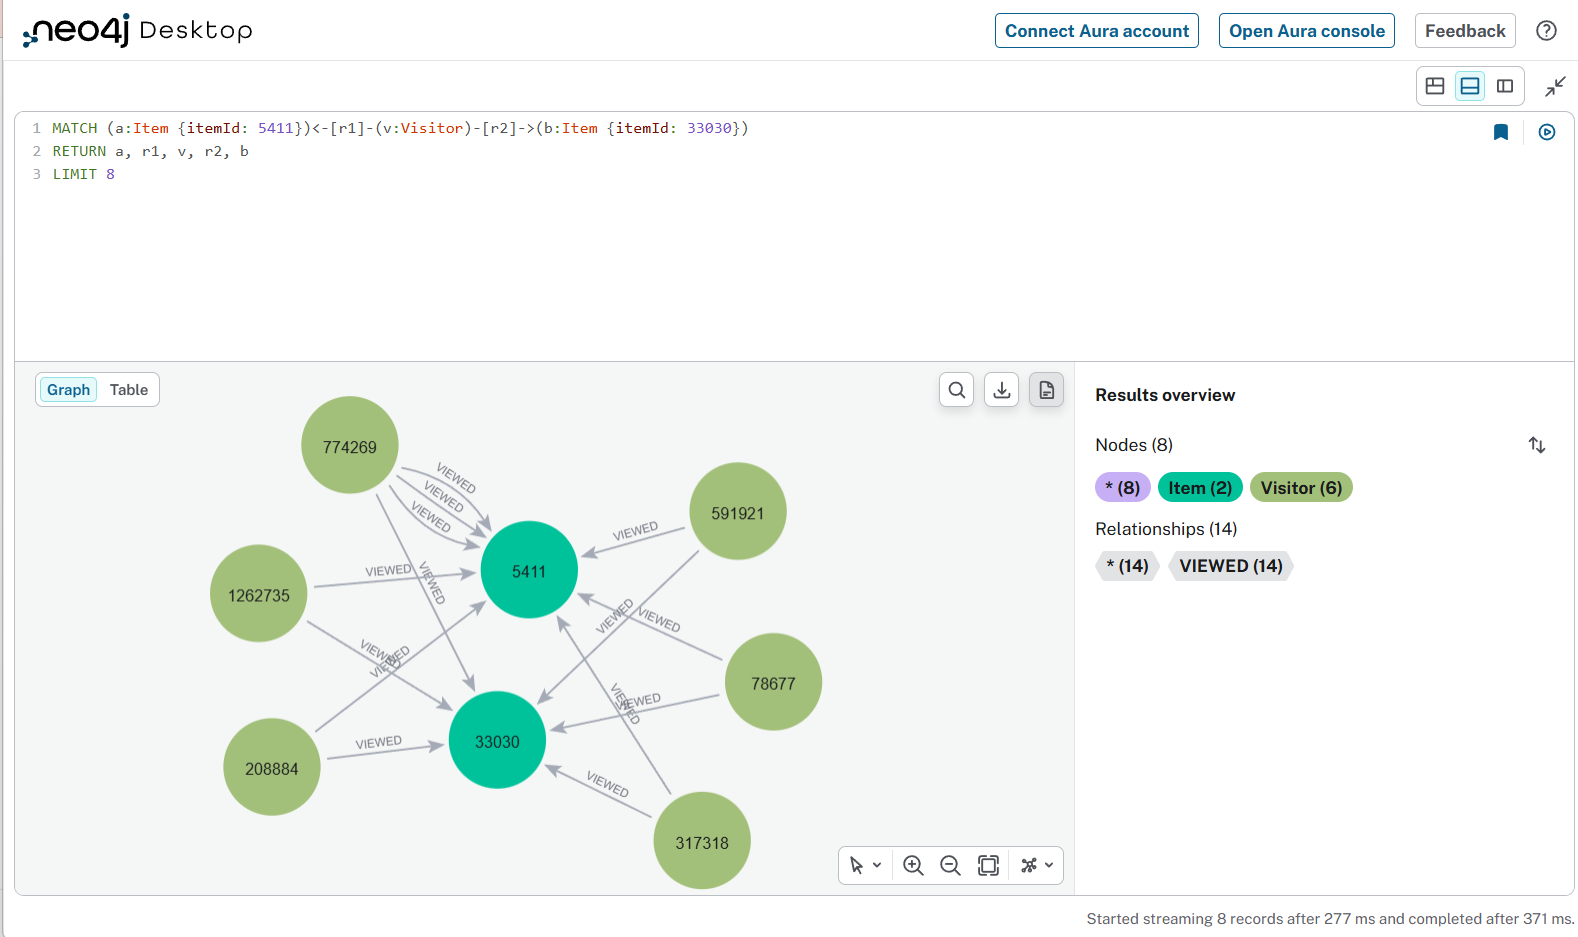

**Graff sesudah similarity**

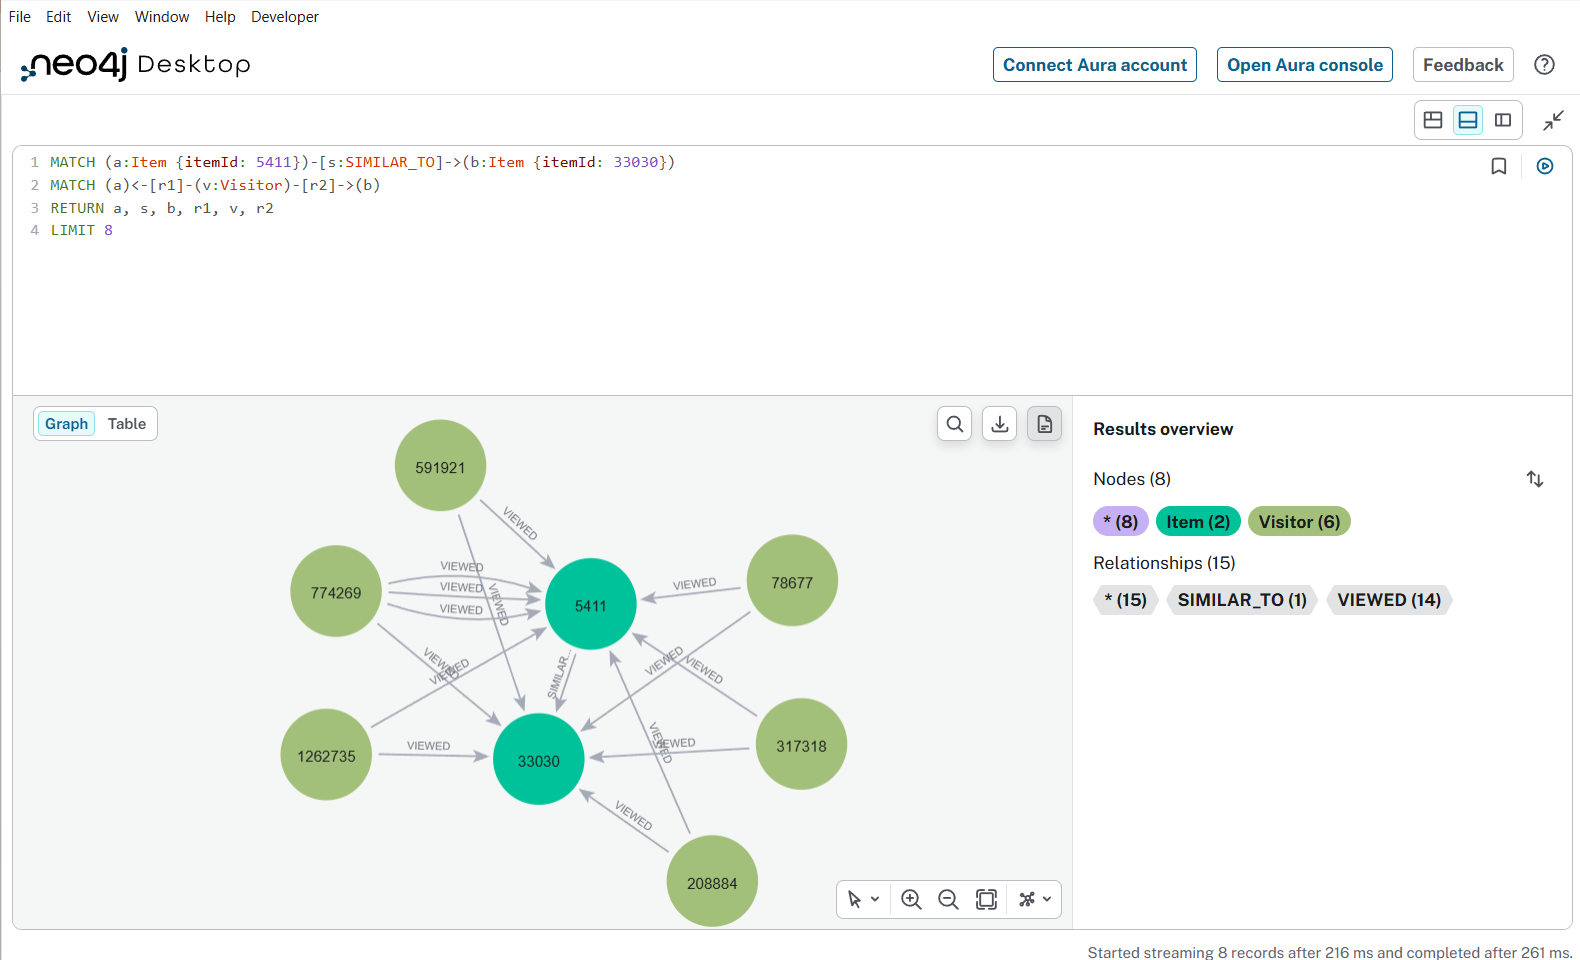

In [39]:
def jumlah_relasi(sertakan_sim):
    kondisi = "" if sertakan_sim else "WHERE type(r) <> 'SIMILAR_TO'"
    q = f"MATCH ()-[r]->() {kondisi} RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY relasi"
    rec, _, _ = driver.execute_query(q, database_=DB, routing_=RoutingControl.READ)
    return pd.DataFrame([r.data() for r in rec])

print("SEBELUM:\n", jumlah_relasi(False))
print("\nSESUDAH:\n", jumlah_relasi(True))

SEBELUM:
           relasi   jumlah
0  ADDED_TO_CART    41699
1         BOUGHT    13626
2         VIEWED  1655412

SESUDAH:
           relasi   jumlah
0  ADDED_TO_CART    41699
1         BOUGHT    13626
2     SIMILAR_TO   134072
3         VIEWED  1655412


## **2.2 Analytics**

### Soal nomor 1
Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

1. tuliskan skrip Python dalam merekomendasikan KNN-nya
2. berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

### Kriteria Pembatasan Kandidat Pengguna untuk Evaluasi

Untuk memastikan proses evaluasi model berjalan secara valid dan objektif, populasi kandidat pengguna (*user*) dibatasi berdasarkan kriteria spesifik berikut:

* **Keaktifan Dua Periode:** *User* wajib tercatat memiliki riwayat transaksi atau interaksi pada data Periode 1 ($P_1$) sekaligus Periode 2 ($P_2$).
* **Ambang Batas Interaksi Awal ($P_1$):** *User* minimal harus telah menyentuh atau berinteraksi dengan **minimal 2 *item*** berbeda pada periode $P_1$.
* **Syarat Eksplorasi Baru ($P_2$):** *User* wajib memiliki **minimal 1 *item* baru** pada periode $P_2$ yang belum pernah muncul sama sekali dalam riwayat interaksi mereka di periode $P_1$.

**Rasionalisasi Teknis:** 
Batasan ini didasarkan pada prinsip kerja sistem rekomendasi yang dirancang khusus untuk memprediksi *item* baru yang belum pernah disentuh oleh pengguna sebelumnya. Oleh karena itu, interaksi terhadap *item* lama yang muncul kembali pada fase $P_2$ secara logis tidak akan mungkin dimasukkan ke dalam daftar rekomendasi sistem. Pembatasan dilakukan untuk menghindari bias dan menjaga validitas metrik akurasi saat evaluasi dilakukan.


In [40]:
test = pd.read_csv("data/events_p2.csv")

hist = df_p1.groupby("visitorid")["itemid"].agg(set)     
fut  = test.groupby("visitorid")["itemid"].agg(set)      

eligible = []
for u in sorted(set(hist.index) & set(fut.index)):
    baru = fut[u] - hist[u]
    if len(hist[u]) >= 2 and len(baru) >= 1:
        eligible.append(u)
print("Jumlah user kandidat:", len(eligible))

SEED = 42
rng = np.random.default_rng(SEED)
USER = int(rng.choice(eligible))
relevan = sorted(fut[USER] - hist[USER])                 

print("User terpilih :", USER)
print("Item di P1    :", len(hist[USER]))
print("Item relevan di P2 (baru):", relevan)

Jumlah user kandidat: 6500
User terpilih : 124912
Item di P1    : 2
Item relevan di P2 (baru): [158962]


### 1.A

In [41]:
q_rekom = """
MATCH (v:Visitor {visitorId: $vid})-[r]->(i:Item)
WITH i, sum(CASE type(r) WHEN 'VIEWED' THEN 1
                         WHEN 'ADDED_TO_CART' THEN 3
                         WHEN 'BOUGHT' THEN 5 ELSE 0 END) AS bobot
MATCH (i)-[s:SIMILAR_TO]->(c:Item)
WHERE NOT EXISTS { MATCH (:Visitor {visitorId: $vid})-->(c) }
RETURN c.itemId AS item,
       sum(bobot * s.score) AS skor,
       count(DISTINCT i) AS didukung_oleh
ORDER BY skor DESC
LIMIT 5
"""

def rekomendasi_knn(driver, user_id, db=DB):
    rec, _, _ = driver.execute_query(q_rekom, vid=int(user_id),
                                     database_=db, routing_=RoutingControl.READ)
    return pd.DataFrame([r.data() for r in rec])

hasil = rekomendasi_knn(driver, USER)
print(hasil)

     item      skor  didukung_oleh
0  387318  1.282164              1
1  181050  1.029645              1
2  179136  0.907719              1
3  130828  0.778680              1
4  359040  0.719847              1


### 1.B

In [42]:
iklan = hasil.head(3)
print("3 item yang diiklankan untuk user", USER, "(k = 5):")
print(iklan)

3 item yang diiklankan untuk user 124912 (k = 5):
     item      skor  didukung_oleh
0  387318  1.282164              1
1  181050  1.029645              1
2  179136  0.907719              1


### Soal nomor 2
Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
1. Hit@5
2. NDCG@5

In [43]:
def hit_at_k(rekom, relevan, k=5):
    return int(any(i in set(relevan) for i in rekom[:k]))

def ndcg_at_k(rekom, relevan, k=5):
    rel = set(relevan)
    dcg  = sum(1 / np.log2(pos + 2) for pos, i in enumerate(rekom[:k]) if i in rel)
    idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(rel), k)))
    return dcg / idcg if idcg > 0 else 0.0

rekom5 = hasil["item"].astype(int).tolist()
rekom3 = rekom5[:3]

print("Rekomendasi top-5:", rekom5)
print("Item relevan (P2) :", relevan)
print(f"Hit@5  = {hit_at_k(rekom5, relevan):d}")
print(f"NDCG@5 = {ndcg_at_k(rekom5, relevan):.4f}")
print("--- jika hanya 3 item iklan ---")
print(f"Hit@3  = {hit_at_k(rekom3, relevan, 3):d} | NDCG@3 = {ndcg_at_k(rekom3, relevan, 3):.4f}")

Rekomendasi top-5: [387318, 181050, 179136, 130828, 359040]
Item relevan (P2) : [158962]
Hit@5  = 0
NDCG@5 = 0.0000
--- jika hanya 3 item iklan ---
Hit@3  = 0 | NDCG@3 = 0.0000


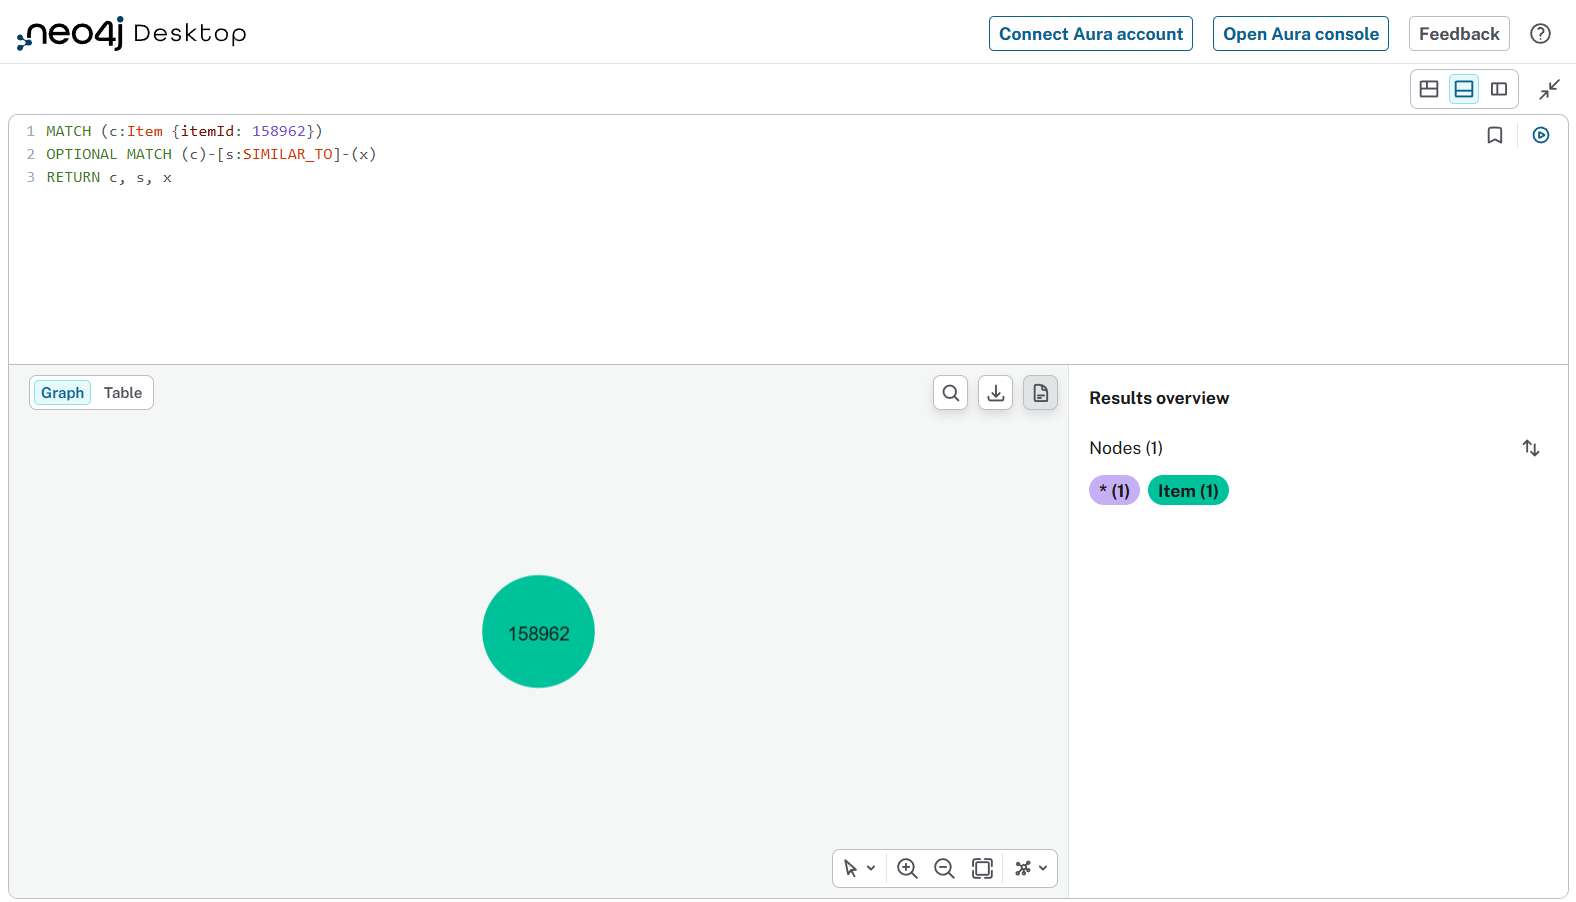

Bukti siapa saja yang menyentuh

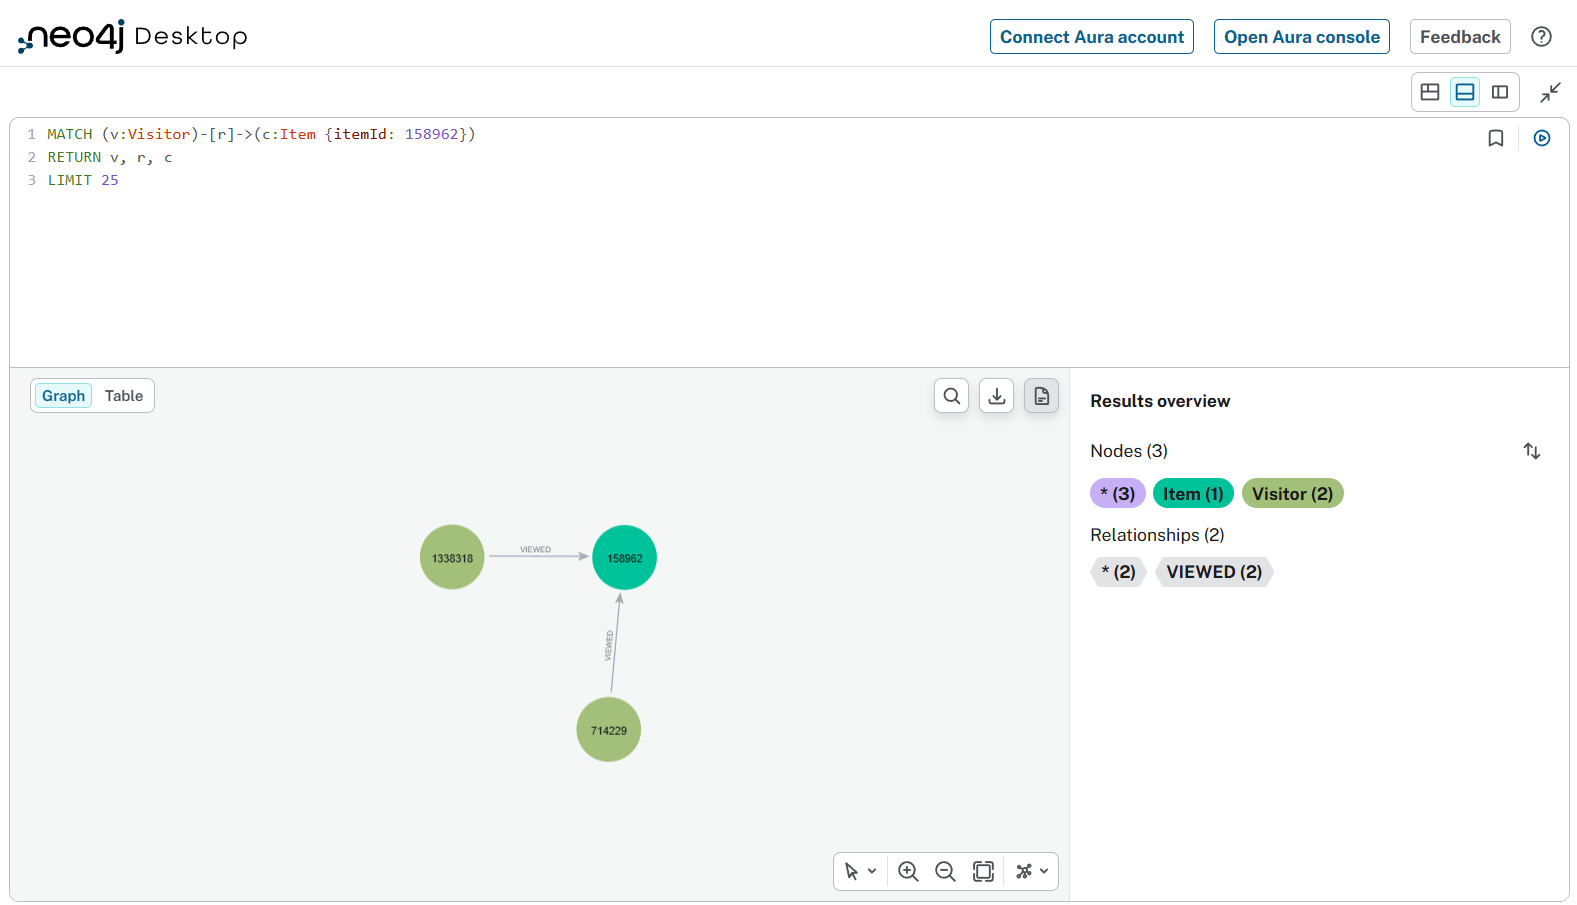

In [45]:
j = int(np.where(i_index == 158962)[0][0])
print("Jumlah user yang menyentuh item 158962 di P1:", user_per_item[j])


item_dengan_sim = set(sim["itemA"]) | set(sim["itemB"])
print("Item yang punya relasi SIMILAR_TO:", f"{len(item_dengan_sim):,}", "dari", f"{n_item:,}",
      f"({len(item_dengan_sim)/n_item:.1%})")

Jumlah user yang menyentuh item 158962 di P1: 2
Item yang punya relasi SIMILAR_TO: 38,657 dari 191,284 (20.2%)


Berdasarkan pengujian pada pengguna terpilih (*user seed 42*), sistem menghasilkan rekomendasi berupa lima *item* terbaik, yaitu: **387318, 181050, 179136, 130828, dan 359040**. Namun, pada data uji (P2), pengguna tersebut tercatat hanya melakukan interaksi dengan satu *item* baru, yaitu **158962**. Karena *item* aktual tersebut tidak masuk ke dalam daftar lima *item* yang direkomendasikan oleh sistem, nilai metrik **Hit@5** dan **NDCG@5** untuk pengguna ini bernilai **0 (nol)**.

Kondisi tersebut terjadi akibat beberapa karakteristik struktural data dan keterbatasan algoritma antaralain:

* **Kendala Relasi pada Graf (P1):** *Item* 158962 sebenarnya eksis pada graf periode pertama (P1), namun hanya memiliki riwayat interaksi dengan dua pengguna saja. 
* **Aturan Kebersamaan Interaksi (*Co-occurrence Constraint*):** Dalam perhitungan kemiripan (*similarity*), sebuah relasi kemiripan hanya akan terbentuk jika sepasang *item* disentuh oleh minimal dua pengguna yang sama. Karena *item* 158962 tidak memiliki pasangan *item* lain yang memenuhi ambang batas kebersamaan tersebut, *item* ini sama sekali tidak memiliki relasi SIMILAR_TO, baik yang bersifat masuk (*in-degree*) maupun keluar (*out-degree*).
* **Keterbatasan Penelusuran KNN:** Algoritma *K-Nearest Neighbors* (KNN) bekerja dengan cara menelusuri jaringan relasi SIMILAR_TO dari daftar *item* yang pernah diinteraksikan oleh pengguna. Akibat ketiadaan relasi tersebut, *item* 158962 secara matematis tidak akan pernah bisa dijangkau atau muncul sebagai kandidat rekomendasi.

**Dampak Sparsity dan Fenomena Long-Tail:**
Secara agregat, hanya **20,2%** dari total *item* (atau sebanyak **38.657 dari 191.284 item**) yang berhasil membentuk relasi SIMILAR_TO. Hal ini mengindikasikan bahwa mayoritas besar katalog produk berada di luar jangkauan model rekomendasi. Fenomena ini dipicu oleh tingkat kelangkaan data (*sparsity*) yang sangat ekstrem (**99,9992%**) serta karakteristik *Long-Tail* yang kuat, di mana sebagian besar *item* hanya memiliki volume interaksi yang sangat sedikit. 

Dengan demikian, perolehan nilai Hit@5 dan NDCG@5 sebesar nol pada kasus pengguna ini murni mencerminkan keterbatasan fundamental dari metode *Collaborative Filtering* berbasis graf dalam menangani masalah kelangkaan interaksi pada produk tidak populer (*cold-start / long-tail items*), dan bukan disebabkan oleh kesalahan implementasi sistem.
